# Q-Learning sur MountainCar-v0
## Phases 1 et 2 : Business Understanding · Data Acquisition & Understanding


**Projet AML – ESPRIT 4DAS**

**Équipe :** Kawther Amri · Balkiss Youssfi · Loussaif Bhiri · Manar Fares · Yasmine Maatougui · Khairi Charrad

**Encadrante :** Wiem Trabelsi

**Livrables du projet :** notebook Python, rapport PDF, présentation PowerPoint, README, références

Article de référence : *Modelling a Reinforcement Learning Agent For Mountain Car Problem Using Q-Learning With Tabular Discretization* (IEEE MysuruCon 2022)

---

### Plan du projet
| Phase | Contenu | Où |
|---|---|---|
| 1 | Business Understanding | ce notebook |
| 2 | Data Acquisition & Understanding (MDP, environnement, collecte) | ce notebook |
| 3 | Data Preparation : discrétisation des états | à venir |
| 4 | Modeling : Q-Learning, comparaison avec SARSA | à venir |
| 5 | Evaluation : critères de la section 1.4 | à venir |

### Comment lire ce notebook
Chaque valeur choisie est justifiée, soit par un encadré **Pourquoi ?** dans le texte, soit par un commentaire `# POURQUOI` dans le code. On distingue toujours :
- les valeurs **imposées par l'environnement** (bornes, force, gravité, limite de 200 pas) : elles sont **lues dans Gymnasium** et non recopiées à la main ;
- les valeurs **choisies par l'équipe** (γ, nombre d'épisodes, seuils de réussite, taille de grille) : elles sont justifiées et pourront être remises en cause.

---
# Phase 1 : Business Understanding

## 1.1 Contexte

Une voiture est placée au fond d'une vallée entre deux collines. Elle doit atteindre un drapeau au sommet de la colline de droite. Son moteur est **trop faible pour monter directement** : la seule stratégie gagnante consiste à reculer d'abord vers la gauche pour prendre de l'élan, puis à accélérer vers la droite.

Ce problème, proposé par Moore (1990), est un banc d'essai classique de l'apprentissage par renforcement. Il représente une famille de problèmes réels où :
- la bonne décision va d'abord **à l'opposé du but** (sacrifier un gain immédiat pour un gain futur) ;
- la récompense utile arrive **tard** ;
- personne ne fournit la bonne réponse : il faut apprendre **par essai-erreur**.

**Domaines d'application** de ce type de problème : robotique (contrôle moteur), véhicules autonomes, gestion d'énergie, jeux, optimisation de systèmes.

## 1.2 Problème à résoudre

> Construire un agent qui apprend **seul**, sans connaître la physique de la voiture, une stratégie lui permettant d'atteindre le drapeau **le plus rapidement possible**.

**Pourquoi l'apprentissage par renforcement ?**

| Type d'apprentissage | Principe | Adapté ici ? |
|---|---|---|
| Supervisé | apprend à partir de données étiquetées (bonnes réponses connues) | Non : personne ne connaît la bonne action dans chaque état |
| Non supervisé | cherche des structures dans des données sans étiquette | Non : il faut prendre des décisions, pas regrouper des données |
| **Par renforcement** | apprend par interaction, à partir de récompenses | **Oui** : l'agent agit, observe le résultat et s'améliore |

## 1.3 Objectifs

**Objectif métier**
- Obtenir un agent capable d'atteindre le drapeau de façon fiable et rapide, sans règle écrite à la main.

**Objectifs techniques (Machine Learning)**
1. Implémenter un agent **Q-Learning tabulaire** sur MountainCar-v0.
2. Rendre l'espace d'états compatible avec une table, grâce à la **discrétisation**.
3. Gérer le compromis **exploration / exploitation** avec une stratégie ε-greedy.
4. Analyser l'effet des hyperparamètres (nombre d'intervalles, α, γ, ε).
5. Comparer l'approche à l'article de référence et à SARSA.

## 1.4 Critères de réussite

| Critère | Mesure | Seuil visé | Pourquoi ce seuil ? |
|---|---|---|---|
| Fiabilité | taux de réussite sur 100 épisodes de test, sans exploration (ε = 0) | ≥ 90 % | choix d'équipe : un agent qui échoue plus d'une fois sur dix n'est pas « fiable » |
| Rapidité | récompense moyenne en test (= − nombre de pas) | > −160 (moins de 160 pas) | choix d'équipe : objectif intermédiaire réaliste pour une table discrétisée. Le seuil officiel « résolu » de Gymnasium est plus exigeant ; il est **lu et affiché** en 2.B.2 |
| Gain par rapport à la référence | récompense moyenne de l'agent entraîné − celle de l'agent aléatoire | ≥ 40 pas | c'est la conséquence des deux lignes précédentes : (−160) − (−200) = 40 |
| Convergence | premier épisode où la moyenne glissante **sur 100 épisodes** dépasse −160 | atteint avant la fin de l'entraînement | la fenêtre de 100 épisodes est celle du critère officiel de Gymnasium |
| Reproductibilité | écart-type de la récompense moyenne de test sur **5 graines** | < 10 pas | choix d'équipe : 5 graines = compromis entre temps de calcul et fiabilité de l'estimation |
| Position par rapport à une heuristique simple | récompense moyenne vs politique « pousser dans le sens de la vitesse » | indicatif | cette règle écrite à la main donne une borne réaliste ; elle est mesurée en 2.C.4 |

> Ces seuils sont des **choix d'équipe** (ils ne sont pas extraits de l'article) : ils sont à valider avec l'encadrante.

La **référence (baseline)** à battre est un agent qui choisit ses actions au hasard ; elle est mesurée en 2.C.4.

## 1.5 Contraintes, hypothèses et risques

**Contraintes**
- Méthode imposée : Q-Learning **tabulaire** (pas de réseau de neurones).
- Ressources : un ordinateur personnel ; l'entraînement doit rester de l'ordre de quelques minutes à une heure.
- Un épisode est limité à **200 pas** (valeur imposée par l'environnement).

**Hypothèses**
- L'environnement Gymnasium est une simulation fidèle et reproductible du problème. *Vérifiée en 2.B.3.*
- Une discrétisation régulière de l'espace d'états suffit pour apprendre une bonne politique. *À tester en phase 3.*

**Risques identifiés**

| Risque | Conséquence | Réponse prévue |
|---|---|---|
| Récompense très rare (l'agent aléatoire n'atteint presque jamais le drapeau) | aucun signal d'apprentissage au début | initialisation optimiste de Q, exploration bien réglée |
| Discrétisation trop grossière ou trop fine | politique imprécise ou apprentissage trop lent | expérience sur le nombre d'intervalles |
| Instabilité de l'apprentissage | performance qui oscille | évaluation séparée, plusieurs graines |
| Résultats dépendants du hasard | conclusions fragiles | graines fixées, test de robustesse |

> **Pourquoi l'initialisation optimiste de Q fonctionne ici ?** Chaque pas coûte −1, donc toutes les vraies valeurs Q sont **négatives**. Si l'on initialise la table à 0, toute valeur non encore essayée paraît meilleure que la réalité. Dès qu'une action est essayée, sa valeur baisse et elle devient moins attractive que les actions jamais testées : l'agent explore donc **systématiquement**, même avec ε = 0, sans dépendre du hasard.

---
# Phase 2 : Data Acquisition & Understanding

En apprentissage par renforcement, il n'y a **pas de dataset fourni** : les données sont des transitions (état, action, récompense, état suivant) **générées par l'interaction** de l'agent avec l'environnement. Cette phase se déroule en trois parties :
- **2.A** Data Understanding : formulation du problème en MDP ;
- **2.B** Data Acquisition : mise en place et compréhension de l'environnement (la source des données) ;
- **2.C** Data Acquisition & Exploration : collecte, contrôle qualité et exploration des transitions.

---
## 2.A Data Understanding : formulation MDP

Cette étape traduit le problème en langage mathématique : un **Processus de Décision Markovien** (MDP).

### 2.A.0 Les composants du système RL

| Composant | Définition | MountainCar-v0 |
|---|---|---|
| **Agent** | celui qui apprend et décide | le contrôleur de la voiture |
| **Environment** | le monde dans lequel l'agent agit | la vallée et la physique de la voiture |
| **State (s)** | la situation actuelle | (position, vitesse) |
| **Action (a)** | ce que l'agent peut faire | pousser à gauche, ne rien faire, pousser à droite |
| **Reward (r)** | le signal de retour après une action | −1 à chaque pas |
| **Policy (π)** | la stratégie de l'agent pour choisir ses actions | ce que l'agent doit apprendre |

**Objectif de l'agent** : *maximiser la récompense cumulée dans le temps.*

### 2.A.1 Le MDP : (S, A, P, R, γ) et la distribution initiale μ₀

| Élément | Signification | MountainCar-v0 | Pourquoi cette valeur ? |
|---|---|---|---|
| **S** | ensemble des états | s = (x, v), x ∈ [−1,2 ; 0,6], v ∈ [−0,07 ; 0,07] : **continu** | bornes imposées par Gymnasium ; deux variables suffisent à décrire le futur (propriété de Markov, 2.A.3) |
| **A** | ensemble des actions | {0 : pousser à gauche, 1 : ne rien faire, 2 : pousser à droite} : **discret** | défini par l'environnement : 3 actions |
| **P(s′ \| s, a)** | probabilité de transition | la physique de la voiture : **déterministe**, mais **inconnue de l'agent** | c'est ce qui impose une méthode *model-free* (2.A.5) |
| **R(s, a, s′)** | récompense | −1 à chaque pas, **y compris le pas qui atteint le drapeau** | transforme « aller vite » en objectif : plus il y a de pas, plus le total est bas |
| **γ** | importance des récompenses futures | 0,99 | **choix d'équipe**, justifié en 2.A.4 |
| **μ₀** | distribution de l'état initial | x ~ Uniforme[−0,6 ; −0,4], v = 0 | seul élément **aléatoire** de l'environnement ; vérifié en 2.C.2 |

### 2.A.2 Épisodes, états terminaux et troncature

- **Début d'épisode** : x tiré au hasard dans [−0,6 ; −0,4], vitesse nulle (μ₀).
- **État terminal (succès)** : le drapeau est atteint, c'est-à-dire **x ≥ 0,5 ET v ≥ 0**. Dans Gymnasium, la condition complète est `position >= goal_position and velocity >= goal_velocity` avec `goal_velocity = 0`. La condition sur la vitesse ne change presque rien en pratique, mais il faut écrire la règle exacte.
- **Troncature (échec)** : l'épisode est coupé après **200 pas** sans avoir atteint le drapeau. Ce n'est **pas** un état terminal du MDP : c'est une limite de temps imposée de l'extérieur. La différence est essentielle pour la mise à jour de Q (voir 2.A.7).
- **Retour d'un épisode** : comme chaque pas coûte −1, le retour non actualisé vaut **− (nombre de pas)**. Maximiser la récompense revient donc à **atteindre le drapeau le plus vite possible**.

$$G_t = R_{t+1} + \gamma R_{t+2} + \gamma^2 R_{t+3} + \cdots$$

### 2.A.3 Propriété de Markov et dynamique complète

*L'état futur dépend uniquement de l'état actuel et de l'action, pas des états passés.* Gymnasium implémente la dynamique suivante, dans cet ordre :

1. $v_{t+1} = v_t + (a_t - 1)\times F - \cos(3\,x_t)\times g$, avec $F = 0{,}001$ (force du moteur) et $g = 0{,}0025$ (gravité) ;
2. la vitesse est **bornée** : $v_{t+1} \in [-0{,}07\,;\,0{,}07]$ ;
3. $x_{t+1} = x_t + v_{t+1}$, puis la position est **bornée** : $x_{t+1} \in [-1{,}2\,;\,0{,}6]$ ;
4. **butée gauche** : si $x_{t+1} = -1{,}2$ et $v_{t+1} < 0$, alors $v_{t+1} = 0$ (la voiture heurte le mur et s'arrête).

La position x et la vitesse v suffisent : l'historique ne sert à rien. L'état (x, v) est donc **markovien**.

**Pourquoi le terme −cos(3x) × g ?** La hauteur du terrain est $\sin(3x)$ et sa pente vaut $3\cos(3x)$ : la gravité qui tire la voiture le long de la pente est proportionnelle à $\cos(3x)$. Elle est maximale (en valeur absolue) en x = 0 et nulle aux sommets de la pente.

**Pourquoi la voiture ne peut pas monter directement ?** La force du moteur ($F = 0{,}001$) est plus faible que l'effet maximal de la gravité ($g = 0{,}0025$). Le code de 2.B.2 le vérifie à partir des constantes lues dans l'environnement.

**Deux nuances sur la propriété de Markov**
- La limite de 200 pas introduit une dépendance au **temps restant**, qui ne fait pas partie de l'état (x, v). C'est une approximation standard en apprentissage par renforcement.
- Après discrétisation (phase 3), deux états continus différents tomberont dans la même case : la propriété de Markov ne sera plus qu'**approchée**. Il faudra le discuter dans l'analyse des résultats.

### 2.A.4 Choix de γ

**Idée.** γ règle la distance à laquelle l'agent « voit » les conséquences de ses actions : l'**horizon effectif** vaut environ $1/(1-\gamma)$ pas. Or atteindre le drapeau demande de l'ordre d'une à deux centaines de pas (l'heuristique de 2.C.4 y parvient en une centaine de pas environ) : il faut un horizon de cet ordre.

**Argument plus précis que le poids γᵏ.** Comme chaque pas coûte −1, le retour actualisé d'un épisode de n pas vaut

$$G = -\sum_{k=0}^{n-1}\gamma^k = -\frac{1-\gamma^n}{1-\gamma}$$

Pour γ petit, ce retour **sature** vers $-1/(1-\gamma)$ quel que soit n : l'agent ne fait plus la différence entre un trajet court et un trajet long, donc n'a aucune raison d'aller vite. Le tableau suivant le montre.

In [1]:
# POURQUOI cette cellule : comparer trois valeurs de γ sur le critère qui compte vraiment,
# c'est-à-dire la capacité à distinguer un trajet de 100 pas d'un trajet de 200 pas.
import numpy as np
import pandas as pd

GAMMAS = [0.9, 0.95, 0.99]


def retour_actualise(gamma, n):
    # Somme géométrique des n récompenses de -1 : -(1 - γ^n) / (1 - γ)
    return -(1 - gamma ** n) / (1 - gamma)


lignes = []
for g in GAMMAS:
    lignes.append({
        "γ": g,
        "horizon effectif 1/(1-γ)": round(1 / (1 - g)),
        "poids d'une récompense à 100 pas (γ^100)": g ** 100,
        "retour d'un trajet de 100 pas": retour_actualise(g, 100),
        "retour d'un trajet de 200 pas": retour_actualise(g, 200),
        "écart 200 pas - 100 pas": retour_actualise(g, 200) - retour_actualise(g, 100),
    })
tableau_gamma = pd.DataFrame(lignes).round(4)
tableau_gamma

,γ,horizon effectif 1/(1-γ),poids d'une récompense à 100 pas (γ^100),retour d'un trajet de 100 pas,retour d'un trajet de 200 pas,écart 200 pas - 100 pas
0,0.90,10,0.0000,-9.9997,-10.0000,-0.0003
1,0.95,20,0.0059,-19.8816,-19.9993,-0.1177
2,0.99,100,0.3660,-63.3968,-86.6020,-23.2053


**Lecture et décision.**
- γ = 0,9 : horizon d'environ 10 pas et écart quasi nul entre un trajet court et un trajet long → inadapté.
- γ = 0,95 : horizon d'environ 20 pas, écart encore très faible → insuffisant.
- **γ = 0,99** : horizon d'environ 100 pas, écart net entre les deux trajets → on le retient.

On pourrait aussi prendre γ = 1 (autorisé car les épisodes sont finis), mais γ < 1 stabilise l'apprentissage tabulaire. Le choix 0,99 sera **testé** dans l'analyse des hyperparamètres (objectif technique n°4).

### 2.A.5 Conséquences sur le choix de la méthode

| Constat | Conséquence |
|---|---|
| P est **inconnu** de l'agent | la **Dynamic Programming** (Policy Iteration / Value Iteration) exige un modèle complet → méthode **model-free** |
| Les épisodes peuvent être longs (200 pas) | une méthode **Temporal Difference** (mise à jour après chaque transition, par bootstrapping) est préférable à Monte Carlo, qui attend la fin de l'épisode |
| Les actions sont discrètes (3) | une table Q(s, a) est possible côté actions |
| Les états sont **continus** | il faudra une **discrétisation** des états pour utiliser une table (phase 3) |
| On cherche la politique optimale | **Q-Learning** (off-policy), comparé à **SARSA** (on-policy) |

### 2.A.6 Politique et équations de Bellman

**Politique** : elle associe à chaque état une distribution sur les actions.

$$\pi(a \mid s) = P(\text{prendre l'action } a \text{ dans l'état } s)$$

Une politique **déterministe** choisit une seule action par état ; une politique **stochastique** donne une probabilité à chaque action. La politique ε-greedy utilisée pendant l'apprentissage est stochastique ; la politique finale apprise est déterministe.

**Équation de Bellman d'espérance pour V** *(valeur d'un état sous la politique π = récompense immédiate + valeur actualisée de l'état suivant)* :

$$V^{\pi}(s) = \sum_a \pi(a \mid s) \sum_{s'} P(s' \mid s,a)\left[R(s,a,s') + \gamma V^{\pi}(s')\right]$$

**Équation de Bellman d'espérance pour Q** :

$$Q^{\pi}(s,a) = \sum_{s'} P(s' \mid s,a)\left[R(s,a,s') + \gamma \sum_{a'} \pi(a' \mid s')\,Q^{\pi}(s',a')\right]$$

**Équation de Bellman d'optimalité pour Q** *(c'est celle que le Q-Learning cherche à satisfaire ; le `max` remplace la somme sur la politique)* :

$$Q^*(s,a) = \sum_{s'} P(s' \mid s,a)\left[R(s,a,s') + \gamma \max_{a'} Q^*(s',a')\right], \qquad \pi^*(s) = \arg\max_a Q^*(s,a)$$

**Cas particulier de MountainCar.** L'environnement est déterministe : $s' = f(s,a)$ et $R = -1$. La somme sur s′ disparaît :

$$Q^*(s,a) = -1 + \gamma \max_{a'} Q^*\big(f(s,a),a'\big)$$

(avec $Q^* = 0$ à partir d'un état terminal). L'espérance présente dans la formulation générale est donc inutile ici, mais elle reste valide.

Dans MountainCar, $P$ est **inconnu** de l'agent : on ne peut pas calculer ces sommes directement (limite de la programmation dynamique). La méthode model-free apprend Q **à partir des transitions observées** $(s_t, a_t, r_{t+1}, s_{t+1})$.

### 2.A.7 Conséquence pour la mise à jour de Q : `terminated` ≠ `truncated`

Pour une transition $(s, a, r, s')$, la règle du Q-Learning est :

$$Q(s,a) \leftarrow Q(s,a) + \alpha\Big[\, r + \gamma\,(1-d)\,\max_{a'}Q(s',a') - Q(s,a)\Big]$$

avec $d = 1$ **uniquement si `terminated` est vrai**.

**Pourquoi ne pas mettre d = 1 quand l'épisode est tronqué ?** Une troncature n'est pas une vraie fin : si l'épisode avait continué, la voiture aurait encore accumulé des −1. Poser $d=1$ reviendrait à dire à l'agent que l'état atteint au pas 200 vaut 0, c'est-à-dire **mieux que toutes les vraies valeurs (négatives)** : on introduirait un biais optimiste artificiel. On continue donc à utiliser $\max_{a'} Q(s',a')$ en cas de troncature.

(Pour SARSA, on remplace $\max_{a'}Q(s',a')$ par $Q(s',a')$ où $a'$ est l'action réellement choisie : c'est la seule différence, qui sera étudiée en phase 4.)

C'est pour cette raison que le dataset conserve **deux colonnes séparées**, `terminated` et `truncated`.

---
## 2.B Data Acquisition : l'environnement, source des données

L'environnement est la **source de données** du projet.

### 2.B.1 Installation, imports et paramètres du projet

À exécuter une seule fois si nécessaire :
```
pip install "gymnasium[classic_control]" numpy pandas matplotlib
```
La cellule suivante écrit aussi un `requirements.txt` avec les **versions réellement utilisées**, pour que le projet soit reproductible sur une autre machine.

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import gymnasium as gym

# ---------------------------------------------------------------------------------------------
# Paramètres du projet : tous les choix d'équipe sont regroupés ici et commentés.
# ---------------------------------------------------------------------------------------------
ENV_ID = "MountainCar-v0"

SEED = 42
# POURQUOI 42 : valeur conventionnelle. Seule compte la FIXATION de la graine : elle rend les
# résultats reproductibles. Toute l'aléa passe par (1) env.reset(seed=...) pour l'état initial
# et (2) un générateur np.random.default_rng(seed) pour les actions aléatoires.
# On n'appelle donc plus np.random.seed(SEED) : le générateur global n'est jamais utilisé.

N_EPISODES = 100
# POURQUOI 100 : c'est la taille de la fenêtre du critère officiel de Gymnasium (moyenne sur
# 100 épisodes). 100 épisodes x 200 pas donnent 20 000 transitions au maximum : assez pour
# explorer l'environnement, et quelques secondes de calcul seulement.

GRID = 20
# POURQUOI 20 : grille de 20 x 20 = 400 cases, utilisée ici UNIQUEMENT pour mesurer la couverture
# de l'espace d'états. C'est une valeur de travail ; le vrai nombre d'intervalles sera choisi
# par expérience en phase 3 (discrétisation).

TOL = 1e-5
# POURQUOI 1e-5 : Gymnasium renvoie des float32 (précision relative ~ 1,2e-7). Les valeurs
# restent inférieures à 1,2 en valeur absolue, donc l'erreur d'arrondi attendue est de l'ordre
# de 1e-7. Une tolérance de 1e-5 laisse une marge d'environ 100 sans masquer une vraie erreur.

os.makedirs("data", exist_ok=True)
os.makedirs("results/figures", exist_ok=True)

# Versions utilisées, sauvegardées pour la reproductibilité
versions = {"gymnasium": gym.__version__, "numpy": np.__version__,
            "pandas": pd.__version__, "matplotlib": matplotlib.__version__}
with open("requirements.txt", "w", encoding="utf-8") as f:
    f.write(f"gymnasium[classic_control]=={versions['gymnasium']}\n")
    for nom in ("numpy", "pandas", "matplotlib"):
        f.write(f"{nom}=={versions[nom]}\n")
print("Versions :", versions)

Versions : {'gymnasium': '1.4.0', 'numpy': '2.1.3', 'pandas': '2.2.3', 'matplotlib': '3.10.0'}


### 2.B.2 Création et inspection de l'environnement

On lit les constantes physiques **dans l'environnement** (au lieu de les recopier) : le notebook reste correct même si une version de Gymnasium en change une.

In [3]:
env = gym.make(ENV_ID)
u = env.unwrapped   # accès à l'environnement « brut », qui porte les constantes physiques

# Constantes imposées par l'environnement (lues, jamais recopiées à la main)
ENV_CONST = {
    "force": u.force,                    # puissance du moteur
    "gravity": u.gravity,                # intensité de la gravité
    "min_position": u.min_position,      # butée gauche
    "max_position": u.max_position,      # butée droite
    "max_speed": u.max_speed,            # vitesse maximale en valeur absolue
    "goal_position": u.goal_position,    # position du drapeau
    "goal_velocity": u.goal_velocity,    # vitesse minimale requise au drapeau
}
low, high = env.observation_space.low.copy(), env.observation_space.high.copy()
MAX_STEPS = env.spec.max_episode_steps          # limite de l'épisode
REWARD_THRESHOLD = env.spec.reward_threshold    # seuil officiel « problème résolu »

print("Identifiant            :", env.spec.id)
print("Limite d'un épisode    :", MAX_STEPS, "pas")
print("Seuil officiel résolu  :", REWARD_THRESHOLD, "(récompense moyenne sur 100 épisodes)")
print("Espace des états       :", env.observation_space)
print("  bornes min           :", low, "(position, vitesse)")
print("  bornes max           :", high)
print("Espace des actions     :", env.action_space, "→ 0 = gauche, 1 = rien, 2 = droite")
print("Constantes physiques   :", ENV_CONST)

# Vérification de l'argument de 2.A.3 : le moteur est plus faible que la gravité maximale
print("\nForce du moteur < gravité maximale ?", ENV_CONST["force"] < ENV_CONST["gravity"],
      f"({ENV_CONST['force']} < {ENV_CONST['gravity']}) → la voiture ne peut pas monter directement")

state, info = env.reset(seed=SEED)
print("\nÉtat initial (position, vitesse) :", state)

# Une transition, pour voir la forme des données
next_state, reward, terminated, truncated, info = env.step(2)
print("Après l'action 2 (droite) :", next_state, "| récompense :", reward,
      "| terminé :", terminated, "| tronqué :", truncated)
env.close()

Identifiant            : MountainCar-v0
Limite d'un épisode    : 200 pas
Seuil officiel résolu  : -110.0 (récompense moyenne sur 100 épisodes)
Espace des états       : Box([-1.2  -0.07], [0.6  0.07], (2,), float32)
  bornes min           : [-1.2  -0.07] (position, vitesse)
  bornes max           : [0.6  0.07]
Espace des actions     : Discrete(3) → 0 = gauche, 1 = rien, 2 = droite
Constantes physiques   : {'force': 0.001, 'gravity': 0.0025, 'min_position': -1.2, 'max_position': 0.6, 'max_speed': 0.07, 'goal_position': 0.5, 'goal_velocity': 0}

Force du moteur < gravité maximale ? True (0.001 < 0.0025) → la voiture ne peut pas monter directement

État initial (position, vitesse) : [-0.4452088  0.       ]
Après l'action 2 (droite) : [-4.4479132e-01  4.1747934e-04] | récompense : -1.0 | terminé : False | tronqué : False


### 2.B.3 Vérification de la dynamique (propriété de Markov)

On vérifie que l'état suivant renvoyé par Gymnasium correspond à la formule complète de 2.A.3 (**avec** bornage et butée gauche), et que la règle de succès `terminated` est bien celle de 2.A.2.

**Pourquoi tester plusieurs politiques et plusieurs épisodes ?** Un seul épisode aléatoire reste dans la zone centrale de la vallée et ne teste jamais les cas limites (butée, vitesse maximale). On ajoute donc :
- une politique **« toujours à gauche »**, qui explore la pente gauche ;
- une politique **« suivre la vitesse »** (pousser dans le sens du mouvement), qui prend de l'élan, peut toucher la butée gauche et atteint le drapeau : elle teste donc la condition de succès.

Le tableau indique, pour chaque politique, **combien de pas touchent réellement la butée gauche** : si ce nombre est nul, le cas limite n'a pas été exercé par cette politique.

In [4]:
def dynamique(x, v, a, c=ENV_CONST):
    # Reproduit la physique de 2.A.3, dans le même ordre que Gymnasium.
    v2 = v + (a - 1) * c["force"] - np.cos(3 * x) * c["gravity"]
    v2 = np.clip(v2, -c["max_speed"], c["max_speed"])                # bornage de la vitesse
    x2 = np.clip(x + v2, c["min_position"], c["max_position"])       # bornage de la position
    if x2 == c["min_position"] and v2 < 0:                           # butée gauche
        v2 = 0.0
    # Condition de succès COMPLÈTE : position ET vitesse
    terminated = bool(x2 >= c["goal_position"] and v2 >= c["goal_velocity"])
    return x2, v2, terminated


# Trois politiques simples, utilisées ici et pour la baseline (2.C.4)
def politique_aleatoire(state, rng):
    return int(rng.integers(3))          # 0, 1 ou 2 avec la même probabilité


def politique_gauche(state, rng):
    return 0                             # toujours pousser à gauche


def politique_vitesse(state, rng):
    return 2 if state[1] >= 0 else 0     # pousser dans le sens de la vitesse actuelle


def verifier_dynamique(politique, n_episodes=20, seed=SEED):
    rng = np.random.default_rng(seed)
    env = gym.make(ENV_ID)
    ecart_max, n_pas, n_butee, n_incoherences = 0.0, 0, 0, 0
    for ep in range(n_episodes):
        state, _ = env.reset(seed=seed + ep)
        done = False
        while not done:
            a = politique(state, rng)
            x2, v2, terminated_attendu = dynamique(float(state[0]), float(state[1]), a)
            state, _, terminated, truncated, _ = env.step(a)
            ecart_max = max(ecart_max, abs(state[0] - x2), abs(state[1] - v2))
            n_incoherences += int(terminated != terminated_attendu)
            n_butee += int(x2 == ENV_CONST["min_position"])
            n_pas += 1
            done = terminated or truncated
    env.close()
    return {"pas testés": n_pas, "écart max": ecart_max,
            "pas contre la butée gauche": n_butee, "règle de succès incohérente": n_incoherences}


resultats = {nom: verifier_dynamique(pol) for nom, pol in
             [("aléatoire", politique_aleatoire), ("toujours à gauche", politique_gauche),
              ("suivre la vitesse", politique_vitesse)]}
verif = pd.DataFrame(resultats).T
affichage = verif.copy()
affichage["écart max"] = verif["écart max"].map(lambda z: f"{z:.2e}")
for col in ["pas testés", "pas contre la butée gauche", "règle de succès incohérente"]:
    affichage[col] = verif[col].astype(int)
print(affichage.to_string())

ok = (verif["écart max"] < TOL).all() and (verif["règle de succès incohérente"] == 0).all()
print("\n→ dynamique déterministe et markovienne confirmée" if ok else "\n→ écart inattendu : à analyser")

                   pas testés écart max  pas contre la butée gauche  règle de succès incohérente
aléatoire                4000  5.86e-08                           0                            0
toujours à gauche        4000  5.85e-08                           0                            0
suivre la vitesse        2395  1.12e-07                           8                            0

→ dynamique déterministe et markovienne confirmée


### 2.B.4 Le terrain : forme de la colline

La hauteur du terrain est donnée par sin(3x). Le graphique montre la vallée, la zone de départ, la butée gauche et le drapeau.

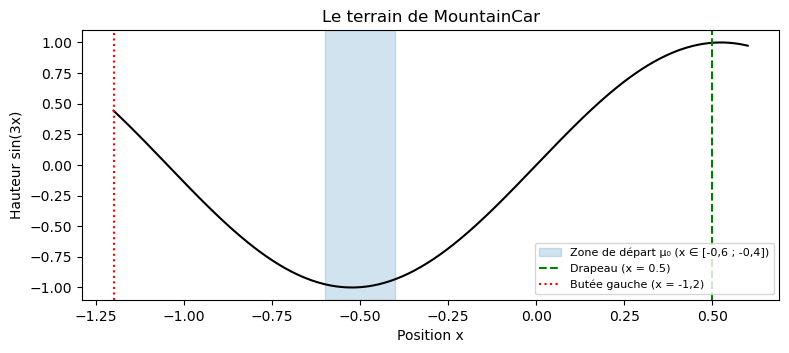

In [5]:
x = np.linspace(ENV_CONST["min_position"], ENV_CONST["max_position"], 300)
plt.figure(figsize=(9, 3.5))
plt.plot(x, np.sin(3 * x), color="black")
plt.axvspan(-0.6, -0.4, color="tab:blue", alpha=0.2, label="Zone de départ μ₀ (x ∈ [-0,6 ; -0,4])")
plt.axvline(ENV_CONST["goal_position"], color="green", linestyle="--",
            label=f"Drapeau (x = {ENV_CONST['goal_position']})")
plt.axvline(ENV_CONST["min_position"], color="red", linestyle=":", label="Butée gauche (x = -1,2)")
plt.xlabel("Position x")
plt.ylabel("Hauteur sin(3x)")
plt.title("Le terrain de MountainCar")
plt.legend(fontsize=8)
plt.savefig("results/figures/terrain.png", dpi=150, bbox_inches="tight")
plt.show()

### 2.B.5 Dictionnaire des données

| Variable | Type | Domaine | Description |
|---|---|---|---|
| `politique` | texte | {aleatoire, vitesse} | politique qui a généré la transition |
| `episode` | entier | 0 … N−1 | numéro de l'épisode |
| `step` | entier | 0 … 199 | numéro du pas dans l'épisode |
| `position` | réel | [−1,2 ; 0,6] | position de la voiture **avant** l'action |
| `velocity` | réel | [−0,07 ; 0,07] | vitesse de la voiture **avant** l'action |
| `action` | entier | {0, 1, 2} | action choisie |
| `reward` | réel | constante = −1 | récompense reçue (aussi au pas terminal) |
| `next_position` | réel | [−1,2 ; 0,6] | position **après** l'action |
| `next_velocity` | réel | [−0,07 ; 0,07] | vitesse **après** l'action |
| `terminated` | booléen | — | drapeau atteint : position ≥ 0,5 **et** vitesse ≥ 0 |
| `truncated` | booléen | — | limite de 200 pas atteinte (≠ état terminal, voir 2.A.7) |

---
## 2.C Data Acquisition & Exploration : collecte des transitions

Chaque interaction donne une **transition** :

$$(s_t,\ a_t,\ r_{t+1},\ s_{t+1},\ \text{done})$$

On collecte des transitions avec un **agent aléatoire**, on contrôle leur qualité, on mesure la **baseline** à battre (agent aléatoire, et en complément une heuristique simple) et on sauvegarde le dataset.

### 2.C.1 Collecte des transitions

On fait jouer l'agent aléatoire pendant `N_EPISODES` épisodes et on enregistre chaque transition. Ces données servent à comprendre l'environnement et à mesurer la référence ; l'agent Q-Learning générera ensuite ses propres données pendant l'entraînement.

On collecte aussi les transitions de la politique **« suivre la vitesse »** : ce n'est **pas** l'objectif du projet (on veut un agent qui apprend sans règle écrite à la main), mais cela donne une référence réaliste de ce qu'il est possible d'atteindre.

In [6]:
def collecter(politique, nom, n_episodes=N_EPISODES, seed=SEED):
    # POURQUOI un seul générateur rng pour les actions et env.reset(seed=seed+ep) pour l'état
    # initial : chaque épisode a son propre état initial reproductible, et la suite d'actions
    # aléatoires est reproductible aussi. Deux sources d'aléa, deux graines contrôlées.
    env = gym.make(ENV_ID)
    rng = np.random.default_rng(seed)
    lignes = []
    for ep in range(n_episodes):
        state, _ = env.reset(seed=seed + ep)
        done, step = False, 0
        while not done:
            action = politique(state, rng)
            next_state, reward, terminated, truncated, _ = env.step(action)
            lignes.append({
                "politique": nom, "episode": ep, "step": step,
                "position": float(state[0]), "velocity": float(state[1]),
                "action": action, "reward": reward,
                "next_position": float(next_state[0]), "next_velocity": float(next_state[1]),
                "terminated": terminated, "truncated": truncated,
            })
            state, step = next_state, step + 1
            done = terminated or truncated
    env.close()
    return pd.DataFrame(lignes)


df = collecter(politique_aleatoire, "aleatoire")
df_vitesse = collecter(politique_vitesse, "vitesse")
print("Agent aléatoire  : ", len(df), "transitions |", df["episode"].nunique(), "épisodes")
print("Suivre la vitesse: ", len(df_vitesse), "transitions |", df_vitesse["episode"].nunique(), "épisodes")
df.head()

Agent aléatoire  :  20000 transitions | 100 épisodes
Suivre la vitesse:  12019 transitions | 100 épisodes


,politique,episode,step,position,velocity,action,reward,next_position,next_velocity,terminated,truncated
0,aleatoire,0,0,-0.445209,0.000000,0,-1.0,-0.446791,-0.001583,False,False
1,aleatoire,0,1,-0.446791,-0.001583,2,-1.0,-0.447945,-0.001153,False,False
2,aleatoire,0,2,-0.447945,-0.001153,1,-1.0,-0.449661,-0.001716,False,False
3,aleatoire,0,3,-0.449661,-0.001716,1,-1.0,-0.451927,-0.002266,False,False
4,aleatoire,0,4,-0.451927,-0.002266,1,-1.0,-0.454726,-0.002799,False,False


### 2.C.2 Contrôle de la qualité des données

On vérifie non seulement les bornes, mais aussi la **cohérence interne** du dataset (continuité entre transitions, état initial, règle de succès).

In [7]:
def controler(d):
    eps = 1e-6   # POURQUOI : tolérance sur les bornes, car les bornes de Gymnasium sont en float32
    dernier_pas = d.groupby("episode").cumcount(ascending=False) == 0
    prev_pos = d.groupby("episode")["next_position"].shift(1)
    prev_vit = d.groupby("episode")["next_velocity"].shift(1)
    pas_par_episode = d.groupby("episode")["step"].count()
    debut = d[d["step"] == 0]

    return {
        "Aucune valeur manquante": d.isna().sum().sum() == 0,
        "Positions dans les bornes (avant et après)":
            d[["position", "next_position"]].stack().between(low[0] - eps, high[0] + eps).all(),
        "Vitesses dans les bornes (avant et après)":
            d[["velocity", "next_velocity"]].stack().between(low[1] - eps, high[1] + eps).all(),
        "Actions dans {0, 1, 2}": d["action"].isin([0, 1, 2]).all(),
        "Récompense toujours égale à -1 (y compris au pas terminal)": (d["reward"] == -1).all(),
        f"Au plus {MAX_STEPS} pas par épisode": pas_par_episode.max() <= MAX_STEPS,
        "État initial : x dans [-0,6 ; -0,4] et v = 0":
            debut["position"].between(-0.6 - eps, -0.4 + eps).all() and (debut["velocity"] == 0).all(),
        "Continuité : l'état d'arrivée d'un pas est l'état de départ du suivant":
            bool(((d["position"] - prev_pos).abs().dropna() < 1e-9).all()
                 and ((d["velocity"] - prev_vit).abs().dropna() < 1e-9).all()),
        "Succès (terminated) ⇒ x ≥ 0,5 et v ≥ 0":
            bool(((d.loc[d["terminated"], "next_position"] >= ENV_CONST["goal_position"] - eps).all())
                 and ((d.loc[d["terminated"], "next_velocity"] >= ENV_CONST["goal_velocity"] - eps).all())),
        "Chaque épisode se termine par terminated ou truncated, et jamais avant":
            bool((d.loc[dernier_pas, ["terminated", "truncated"]].any(axis=1)).all()
                 and not d.loc[~dernier_pas, ["terminated", "truncated"]].any(axis=None)),
        "truncated seulement au dernier pas autorisé":
            bool((d.loc[d["truncated"], "step"] == MAX_STEPS - 1).all()),
    }


for nom_df, d in [("aléatoire", df), ("suivre la vitesse", df_vitesse)]:
    print(f"--- Contrôles pour la politique : {nom_df} ---")
    for nom, ok in controler(d).items():
        print(("✅ " if ok else "❌ ") + nom)
    print()

print(df.dtypes)

--- Contrôles pour la politique : aléatoire ---
✅ Aucune valeur manquante
✅ Positions dans les bornes (avant et après)
✅ Vitesses dans les bornes (avant et après)
✅ Actions dans {0, 1, 2}
✅ Récompense toujours égale à -1 (y compris au pas terminal)
✅ Au plus 200 pas par épisode
✅ État initial : x dans [-0,6 ; -0,4] et v = 0
✅ Continuité : l'état d'arrivée d'un pas est l'état de départ du suivant
✅ Succès (terminated) ⇒ x ≥ 0,5 et v ≥ 0
✅ Chaque épisode se termine par terminated ou truncated, et jamais avant
✅ truncated seulement au dernier pas autorisé

--- Contrôles pour la politique : suivre la vitesse ---
✅ Aucune valeur manquante
✅ Positions dans les bornes (avant et après)
✅ Vitesses dans les bornes (avant et après)
✅ Actions dans {0, 1, 2}
✅ Récompense toujours égale à -1 (y compris au pas terminal)
✅ Au plus 200 pas par épisode
✅ État initial : x dans [-0,6 ; -0,4] et v = 0
✅ Continuité : l'état d'arrivée d'un pas est l'état de départ du suivant
✅ Succès (terminated) ⇒ x ≥ 0,5 e

In [8]:
df[["position", "velocity", "next_position", "next_velocity"]].describe().round(4)

,position,velocity,next_position,next_velocity
count,20000.0000,20000.0000,20000.0000,20000.0000
mean,-0.5266,-0.0003,-0.5268,-0.0003
std,0.0845,0.0071,0.0847,0.0071
min,-0.9051,-0.0303,-0.9051,-0.0303
25%,-0.5803,-0.0048,-0.5805,-0.0048
50%,-0.5254,-0.0004,-0.5257,-0.0004
75%,-0.4729,0.0042,-0.4732,0.0042
max,-0.2060,0.0274,-0.2060,0.0274


### 2.C.3 Lecture des statistiques descriptives
Les statistiques ci-dessus montrent l'étendue réellement explorée par l'agent aléatoire, à comparer aux bornes de l'environnement (position [−1,2 ; 0,6], vitesse [−0,07 ; 0,07]). L'écart entre les deux est la première indication de la difficulté du problème : **un agent qui agit au hasard reste dans une petite zone autour du point de départ**. La section 2.C.5 quantifie cette couverture.

### 2.C.4 Baselines : agent aléatoire et heuristique « suivre la vitesse »

Deux références :
- l'**agent aléatoire** : le niveau « sans intelligence » à battre (critère « gain par rapport à la référence ») ;
- l'**heuristique « suivre la vitesse »** : une règle écrite à la main qui donne une idée de ce qui est atteignable. Elle sert de **repère**, pas d'objectif.

**Pourquoi ajouter une seconde référence ?** L'agent aléatoire a probablement une récompense identique à chaque épisode (écart-type nul) : il ne permet ni de mesurer une variabilité ni de savoir si le seuil de −160 est réaliste. L'heuristique encadre l'objectif par le haut.

**Correction par rapport à la version précédente :** la position maximale est calculée sur `next_position` (la position **après** l'action). Avec `position`, on oubliait le dernier pas et on sous-estimait la position réellement atteinte.

In [9]:
def resume_episodes(d):
    return d.groupby(["politique", "episode"]).agg(
        recompense=("reward", "sum"),
        pas=("step", "count"),
        reussite=("terminated", "any"),
        position_max=("next_position", "max"),   # next_position : on inclut le dernier pas
    ).reset_index()


episodes_all = resume_episodes(pd.concat([df, df_vitesse], ignore_index=True))

baselines = episodes_all.groupby("politique").agg(
    recompense_moy=("recompense", "mean"),
    recompense_std=("recompense", "std"),
    taux_reussite=("reussite", "mean"),
    pas_moy=("pas", "mean"),
    position_max=("position_max", "max"),
).round(3)
print(baselines.to_string())
print(f"\nSeuil officiel « résolu » de Gymnasium : {REWARD_THRESHOLD}")
print("Répartition des actions de l'agent aléatoire :")
print(df["action"].value_counts(normalize=True).sort_index()
      .rename({0: "gauche", 1: "rien", 2: "droite"}).round(3).to_string())

episodes = episodes_all[episodes_all["politique"] == "aleatoire"]   # utilisé dans la synthèse

           recompense_moy  recompense_std  taux_reussite  pas_moy  position_max
politique                                                                      
aleatoire         -200.00           0.000            0.0   200.00        -0.206
vitesse           -120.19           3.234            1.0   120.19         0.543

Seuil officiel « résolu » de Gymnasium : -110.0
Répartition des actions de l'agent aléatoire :
action
gauche    0.337
rien      0.335
droite    0.327


### 2.C.5 Couverture de l'espace d'états

On mesure quelle part de la grille `GRID` × `GRID` (400 cases) est visitée par chaque politique.

**Correction par rapport à la version précédente :** on utilisait `np.digitize`, qui renvoie des indices de 0 à 21 (deux cases « hors bornes » en plus) ; le « sur 400 » et le `/4` étaient donc approximatifs. `np.histogram2d` compte exactement les cases de la grille.

Agent aléatoire   : 62 cases visitées sur 400 (15.5 %)
Suivre la vitesse : 136 cases visitées sur 400 (34.0 %)


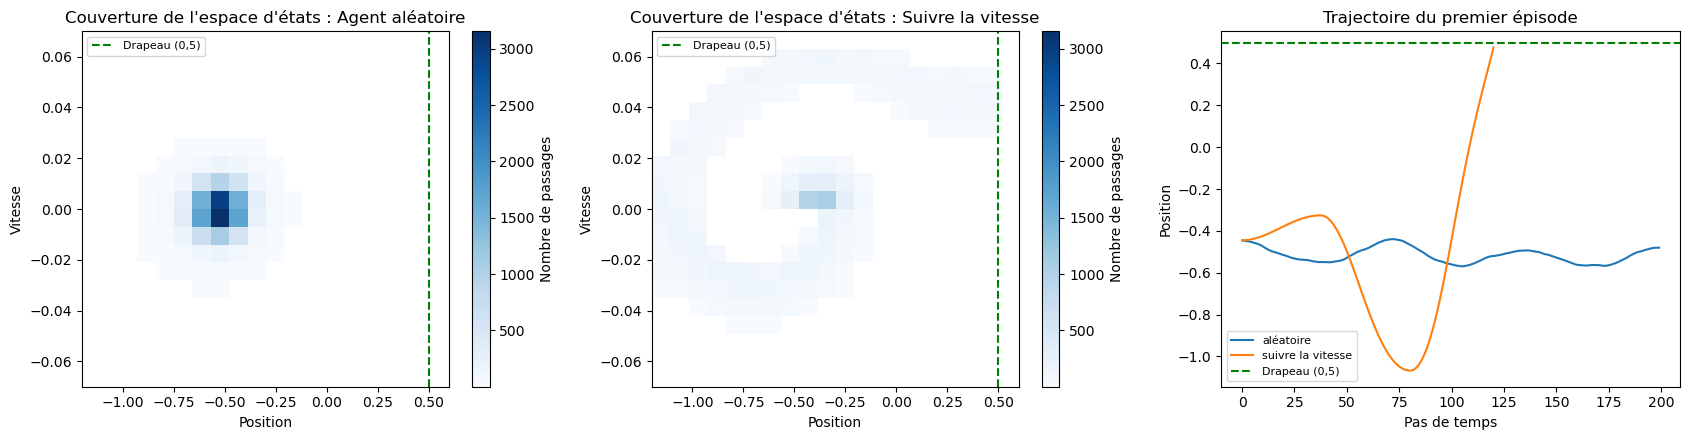

In [10]:
def couverture(d, grid=GRID):
    h, _, _ = np.histogram2d(d["position"], d["velocity"], bins=grid,
                             range=[[low[0], high[0]], [low[1], high[1]]])
    return h, int((h > 0).sum())


h_alea, n_alea = couverture(df)
h_vit, n_vit = couverture(df_vitesse)
n_cases = GRID * GRID
print(f"Agent aléatoire   : {n_alea} cases visitées sur {n_cases} ({100 * n_alea / n_cases:.1f} %)")
print(f"Suivre la vitesse : {n_vit} cases visitées sur {n_cases} ({100 * n_vit / n_cases:.1f} %)")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
vmax = max(h_alea.max(), h_vit.max())
for ax, h, titre in [(axes[0], h_alea, "Agent aléatoire"), (axes[1], h_vit, "Suivre la vitesse")]:
    im = ax.imshow(np.ma.masked_equal(h.T, 0), origin="lower", aspect="auto", cmap="Blues",
                   extent=[low[0], high[0], low[1], high[1]], vmin=1, vmax=vmax)
    ax.axvline(ENV_CONST["goal_position"], color="green", linestyle="--", label="Drapeau (0,5)")
    ax.set_xlabel("Position"); ax.set_ylabel("Vitesse")
    ax.set_title(f"Couverture de l'espace d'états : {titre}")
    ax.legend(fontsize=8)
    fig.colorbar(im, ax=ax, label="Nombre de passages")

# Trajectoire du premier épisode de chaque politique
for d, nom in [(df, "aléatoire"), (df_vitesse, "suivre la vitesse")]:
    ep0 = d[d["episode"] == 0]
    axes[2].plot(ep0["step"], ep0["position"], label=nom)
axes[2].axhline(ENV_CONST["goal_position"], color="green", linestyle="--", label="Drapeau (0,5)")
axes[2].set_xlabel("Pas de temps"); axes[2].set_ylabel("Position")
axes[2].set_title("Trajectoire du premier épisode")
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.savefig("results/figures/data_acquisition.png", dpi=150, bbox_inches="tight")
plt.show()

### 2.C.6 Sauvegarde du dataset

On sauvegarde les transitions de l'agent aléatoire (dataset de la phase 2) et le résumé par épisode des **deux** politiques (pour comparer plus tard l'agent entraîné à ces références).

In [11]:
df.to_csv("data/transitions_agent_aleatoire.csv", index=False)
episodes_all.to_csv("data/baseline_par_episode.csv", index=False)
print("Données sauvegardées :")
print(" - data/transitions_agent_aleatoire.csv  (", len(df), "transitions )")
print(" - data/baseline_par_episode.csv          (", len(episodes_all), "épisodes, 2 politiques )")
print(" - requirements.txt                       (versions utilisées)")

Données sauvegardées :
 - data/transitions_agent_aleatoire.csv  ( 20000 transitions )
 - data/baseline_par_episode.csv          ( 200 épisodes, 2 politiques )
 - requirements.txt                       (versions utilisées)


### 2.C.7 Synthèse

Les chiffres ci-dessous sont **calculés** à partir des données : la conclusion s'appuie sur eux et non sur des valeurs écrites à l'avance.

In [12]:
from IPython.display import Markdown, display

b = baselines.loc["aleatoire"]
v = baselines.loc["vitesse"]
n_tr = f"{len(df):,}".replace(",", " ")
# Le statut des contrôles est calculé, pas affirmé
tous_ok = all(controler(df).values()) and all(controler(df_vitesse).values())
statut = "tous les contrôles de qualité de 2.C.2 sont passés" if tous_ok else "⚠️ au moins un contrôle de 2.C.2 a échoué : voir plus haut"

display(Markdown(f"""
- **{n_tr}** transitions collectées sur **{df['episode'].nunique()}** épisodes (agent aléatoire) ; {statut}.
- **Baseline (agent aléatoire)** : récompense moyenne **{b['recompense_moy']:.1f}** (écart-type {b['recompense_std']:.1f}), réussite **{100 * b['taux_reussite']:.0f} %**, position maximale **{b['position_max']:.3f}** (le drapeau est à {ENV_CONST['goal_position']}).
- **Repère (heuristique « suivre la vitesse »)** : récompense moyenne **{v['recompense_moy']:.1f}**, réussite **{100 * v['taux_reussite']:.0f} %**, en moyenne **{v['pas_moy']:.0f}** pas.
- **Couverture** : l'agent aléatoire visite **{n_alea}** cases sur {n_cases} (**{100 * n_alea / n_cases:.0f} %**) de la grille {GRID} × {GRID} ; l'heuristique en visite **{n_vit}** (**{100 * n_vit / n_cases:.0f} %**).
- **Objectifs de la section 1.4** : battre {b['recompense_moy']:.0f} d'au moins 40 pas (soit viser > {b['recompense_moy'] + 40:.0f}), avec le seuil officiel {REWARD_THRESHOLD} comme objectif ambitieux.
"""))


- **20 000** transitions collectées sur **100** épisodes (agent aléatoire) ; tous les contrôles de qualité de 2.C.2 sont passés.
- **Baseline (agent aléatoire)** : récompense moyenne **-200.0** (écart-type 0.0), réussite **0 %**, position maximale **-0.206** (le drapeau est à 0.5).
- **Repère (heuristique « suivre la vitesse »)** : récompense moyenne **-120.2**, réussite **100 %**, en moyenne **120** pas.
- **Couverture** : l'agent aléatoire visite **62** cases sur 400 (**16 %**) de la grille 20 × 20 ; l'heuristique en visite **136** (**34 %**).
- **Objectifs de la section 1.4** : battre -200 d'au moins 40 pas (soit viser > -160), avec le seuil officiel -110.0 comme objectif ambitieux.


## Conclusion et phase suivante

- Les états sont **continus** : une Q-table ne peut pas les stocker directement → prochaine phase, **Data Preparation : discrétisation des états**. Le nombre d'intervalles sera choisi **par expérience**, en s'appuyant sur la couverture mesurée en 2.C.5.
- La récompense est **toujours −1** tant que le drapeau n'est pas atteint : l'agent ne reçoit presque aucun signal utile au début. C'est la difficulté principale, qui justifie l'initialisation optimiste de Q et un réglage soigné de l'exploration.
- La **baseline à battre** est celle de l'agent aléatoire donnée par la synthèse 2.C.7. Elle est complétée par l'heuristique « suivre la vitesse », qui montre qu'une solution rapide existe.
- Pour la mise à jour de Q, on distinguera **`terminated`** (pas de bootstrap) et **`truncated`** (bootstrap conservé), voir 2.A.7.

---
## Annexe : corrections apportées par rapport à la version précédente

| # | Où | Problème | Correction |
|---|---|---|---|
| 1 | 2.A.2, 2.B.5 | condition de succès incomplète (x ≥ 0,5 seulement) | x ≥ 0,5 **et** v ≥ 0, comme dans Gymnasium |
| 2 | 2.A.3 | bornage et butée gauche absents du texte | dynamique complète en 4 étapes |
| 3 | 2.A.4 | justification de γ imprécise (poids γ¹⁰⁰) | argument de la saturation du retour + tableau comparatif |
| 4 | 1.4 | seuil −160 non justifié, critères vagues | origine de chaque seuil, critères chiffrés, seuil officiel lu dans l'environnement |
| 5 | 2.A.6 | Bellman pour Q écrite avec `max` mais présentée comme générale ; notations S/s mélangées | séparation espérance / optimalité, notation unique, cas déterministe |
| 6 | 2.A.7 | distinction `terminated` / `truncated` non expliquée | section dédiée avec la règle de mise à jour |
| 7 | 2.B.1 | `np.random.seed` inutile ; versions non sauvegardées | un seul mécanisme d'aléa, `requirements.txt` généré |
| 8 | 2.B.2 | constantes physiques recopiées à la main | constantes lues dans `env.unwrapped` |
| 9 | 2.B.3 | dynamique testée sur un seul épisode aléatoire | plusieurs épisodes, 3 politiques, cas limites, test de la règle de succès |
| 10 | 2.C.2 | `gym.make` appelé deux fois sans `close()` ; contrôles limités | environnement créé une fois et fermé ; contrôles de cohérence supplémentaires |
| 11 | 2.C.4 | `position_max` calculée sur `position` | calculée sur `next_position` |
| 12 | 2.C.4 | une seule baseline, écart-type nul | seconde référence (heuristique) |
| 13 | 2.C.5 | couverture calculée avec `np.digitize` (indices 0 à 21) | `np.histogram2d`, 400 cases exactes |
| 14 | conclusion | « −200 / 0 % » écrit avant les résultats | chiffres calculés dans la synthèse |